# DL4CV PA01-Q1: k-Nearest Neighbors



---

### $\color{red}{\textbf{Name and ID:}}$ 202688563 Meng Socheata

Before we start, please put your student ID and your name in following format.
For example

12345678 HONGGildong


---

### Submission

1. The output of the code cells in this `.ipynb` file $\color{red}{\text{MUST}}$ be saved.
   - Save text output of code cells
   - Save graphs and plots of code cells    
2. All The `.py` files should be submitted.
3. zip the required `.ipynb` and `.py` files into $\color{red}{\mathtt{StudentID\_StudentName.zip}}$ and submit.
   - For example `12345678_HONGGildong.zip`
4. Deadline is $\color{red}{2026:09:30-23:59:59}$ (YYYY:MM:DD-HH:MM:SS)

---

### To-do

1. Fill in Your ID and Name.
2. (Programming) In `knn.py`, implement **compute_distances()** function with L2 distance.
3. (Programming) In `knn.py`, implement **compute_distances()** function with L1 distance.
4. (Programming) In `knn.py`, implement **predict_labels()** function.
5. (Programming) In `Q1_knn.ipynb`, implement k-fold cross validation to find the best value of k for kNN.
6. (Save Outputs) Successfully Run all the **code cells** in `Q1_knn.ipynb`, $\color{red}{\text{MUST}}$ save the outputs.
7. Submit $\color{red}{\mathtt{StudentID\_StudentName.zip}}$ file to Plato before deadline.


---

## k-Nearest Neighbor (kNN) Programming Assignment

The kNN classifier consists of two stages:

- During training, the classifier takes the training data as a feature vector and simply remembers it.
- When a new input arrives, compute the distance from the new point to every training point.
- Select the K training points with the smallest distance (the nearest neighbors).
- For classification, return the majority class among the K neighbors.
- Use cross-validation method find best K for kNN.

In this exercise you will implement these steps and understand the basic Image Classification pipeline. Use cross-validation find best k.

---

## Setup Code

### Google Colab Setup (Skip If Run on Local Machine)

Unzip the `PA01.zip` file, upload entire `DeepLearning4ComputerVision` folder into Google drivers `My Drive` folder.

Next we need to run a few commands to set up our environment on Google Colab. 

Run the following cell to mount your Google Drive. Follow the link, sign in to your Google account (the same account you used to store this notebook!) and permit proper authorizations.

(Recommended) If you are running this notebook on a local machine you can **comment out the code** this section and skip this section. 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

GOOGLE_DRIVE_PATH_AFTER_MYDRIVE = 'DeepLearning4ComputerVision/PA01'

import os
import sys

#sys.path.append('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)) # if not working, try this line instead
os.chdir('/content/drive/My Drive/{}'.format(GOOGLE_DRIVE_PATH_AFTER_MYDRIVE))

# Print current working directory
print("Current Working Directory:", os.getcwd())

# List files to make sure your data is visible
print("Available Files:", os.listdir())

If the output shows
> Mounted at /content/drive
> 
> Current Working Directory: /content/drive/My Drive/DeepLearning4ComputerVision/PA01
> 
> Available Files: ['datasets', 'dlcv', 'knn.py', 'softmax.py', ...]

Then, the Google Colab is working correctly.

### python env and ipynb setup (Local Machine Run from here) (Google Colab also run this)

In [3]:
import sys
import importlib
sys.modules["imp"] = importlib
# Notebook will reload external python modules;
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
# This is a bit of magic to make matplotlib figures appear inline in the notebook
# rather than in a new window.
%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Cifar10 Dataset Loading

In [5]:
import random
import numpy as np
from dlcv.data_utils import load_CIFAR10


# Load the raw CIFAR-10 data.
cifar10_dir = 'datasets/cifar-10-batches-py'

# Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
try:
   del X_train, y_train
   del X_test, y_test
   print('Clear previously loaded data.')
except:
   pass

X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

# As a sanity check, we print out the size of the training and test data.
print('Training data shape: ', X_train.shape)
print('Training labels shape: ', y_train.shape)
print('Test data shape: ', X_test.shape)
print('Test labels shape: ', y_test.shape)

Training data shape:  (50000, 32, 32, 3)
Training labels shape:  (50000,)
Test data shape:  (10000, 32, 32, 3)
Test labels shape:  (10000,)


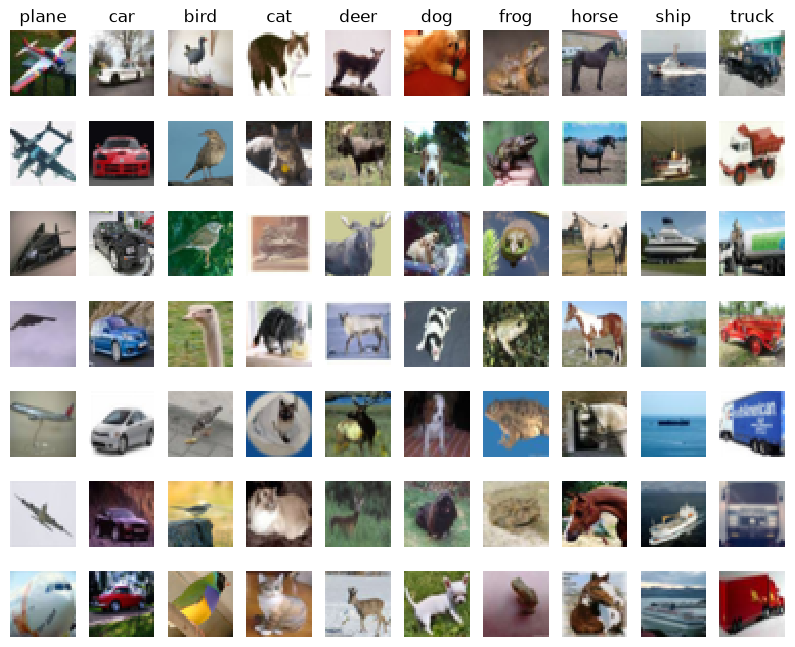

In [6]:
# Visualize some examples from the dataset.
# We show a few examples of training images from each class.
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
num_classes = len(classes)
samples_per_class = 7
for y, cls in enumerate(classes):
    idxs = np.flatnonzero(y_train == y)
    idxs = np.random.choice(idxs, samples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt_idx = i * num_classes + y + 1
        plt.subplot(samples_per_class, num_classes, plt_idx)
        plt.imshow(X_train[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls)
plt.show()

In [7]:
# Subsample the data for more efficient code execution in this exercise
num_training = 5000
mask = list(range(num_training))
X_train = X_train[mask]
y_train = y_train[mask]

num_test = 500
mask = list(range(num_test))
X_test = X_test[mask]
y_test = y_test[mask]

# Reshape the image data into rows
X_train = np.reshape(X_train, (X_train.shape[0], -1))
X_test = np.reshape(X_test, (X_test.shape[0], -1))
print(X_train.shape, X_test.shape)

(5000, 3072) (500, 3072)


## k-Nearest Neighbors (kNN)

Remember that training a kNN classifier has no fancy operations.

the Classifier simply remembers the data and does no further processing


In [8]:
from knn import KNearestNeighbor

# Create a kNN classifier instance.
classifier = KNearestNeighbor()
classifier.train(X_train, y_train)  # remembers the data

### Implement distance computation function

We would now like to classify the test data with the kNN classifier. Recall that we can break down this process into two steps:

1. First we must compute the distances between all test examples and all train examples.
2. Given these distances, for each test example we find the k nearest examples and have them vote for the label

Lets begin with computing the distance matrix between all training and test examples. For example, if there are **Ntr** training examples and **Nte** test examples, this stage should result in a **Nte x Ntr** matrix where each element (i,j) is the distance between the i-th test and j-th train example.

**Note: For the three distance computations that we require you to implement in this notebook, you may not use the np.linalg.norm() function that numpy provides.**

First, open `knn.py` and implement the function `compute_distances` that uses a double loop over all pairs of (test, train) examples and computes the distance matrix one element at a time. For default, use L2 distance. later, use L1 distance as a comparison.

In [9]:
# Open knn.py and implement compute_distances() function.

# Test your implementation:
dists = classifier.compute_distances(X_test)
print(dists.shape)

(500, 5000)


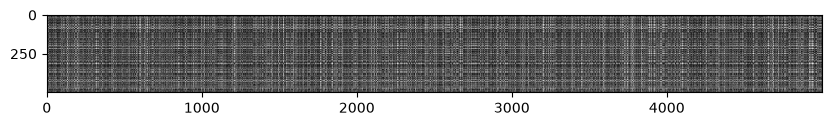

In [10]:
# We can visualize the distance matrix: each row is a single test example and
# its distances to training examples
plt.imshow(dists, interpolation='none')
plt.show()

Notice the structured patterns in the distance matrix, where some rows or columns are visibly brighter. (Note that with the default color scheme black indicates low distances while white indicates high distances.)

## Implement prediction function of kNN method

Given a matrix of distances between test points and training points, predict a label for each test point. Use the distance matrix to find the k nearest neighbors of the ith testing point, and use self.y_train to find the labels of these neighbors.

In [11]:
# Open knn.py and implement predict_labels() function.
# We use k = 1 (which is Nearest Neighbor).
y_test_pred = classifier.predict_labels(dists, k=1)

# Compute and print the fraction of correctly predicted examples
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 137 / 500 correct => accuracy: 0.274000


In [12]:
# We use k = 5 and predict the most common label.
y_test_pred = classifier.predict_labels(dists, k=5)
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 139 / 500 correct => accuracy: 0.278000


You should expect to see a slightly different accuracy between `k = 1` and `k = 5`.

## Implement Cross-validation

We have implemented the k-Nearest Neighbor classifier but we set the value k = 5 arbitrarily. We will now determine the best value of this hyperparameter with cross-validation. 





In [ ]:
num_folds = 5
k_choices = [1, 5, 10, 50]

X_train_folds = []
y_train_folds = []

# Use numpy.array_split function, Split the training data into folds.
# After splitting, X_train_folds and y_train_folds are lists of length num_folds, 
# where y_train_folds[i] is the label vector for the points in X_train_folds[i]. 
X_train_folds = np.array_split(X_train, num_folds)
y_train_folds = np.array_split(y_train, num_folds)

# A dictionary holding the accuracies for different values of k that we find
# when running cross-validation. After running cross-validation,
# k_to_accuracies[k] should be a list of length num_folds giving the different
# accuracy values that we found when using that value of k.
k_to_accuracies = {}


################################################################################
# TODO:                                                                        #
# Perform k-fold cross validation to find the best value of k. For each        #
# possible value of k, run the k-nearest-neighbor algorithm num_folds times,   #
# where in each case you use all but one of the folds as training data and the #
# last fold as a validation set. Store the accuracies for all fold and all     #
# values of k in the k_to_accuracies dictionary.                               #
################################################################################
# Replace "pass" statement with your code
for k in k_choices:
    for fold in range(num_folds): 

        validation_X_test = X_train_folds[fold]
        validation_y_test = y_train_folds[fold]
        temp_X_train = np.concatenate(X_train_folds[:fold] + X_train_folds[fold + 1:])
        temp_y_train = np.concatenate(y_train_folds[:fold] + y_train_folds[fold + 1:])

        test_classifier = KNearestNeighbor()
        test_classifier.train( temp_X_train, temp_y_train )
        
        temp_dists = test_classifier.compute_distances(validation_X_test)
        temp_y_test_pred = test_classifier.predict_labels(temp_dists, k=k)
    
        num_correct = np.sum(temp_y_test_pred == validation_y_test)
        num_test = validation_X_test.shape[0]
        accuracy = float(num_correct) / num_test
        k_to_accuracies[k] = k_to_accuracies.get(k,[]) + [accuracy]
#######################################################################
#                         END OF YOUR CODE                            #
#######################################################################

# Print out the computed accuracies
for k in sorted(k_to_accuracies):
    for accuracy in k_to_accuracies[k]:
        print('k = %d, accuracy = %f' % (k, accuracy))

k = 1, accuracy = 0.263000
k = 1, accuracy = 0.257000
k = 1, accuracy = 0.264000
k = 1, accuracy = 0.278000
k = 1, accuracy = 0.266000
k = 5, accuracy = 0.248000
k = 5, accuracy = 0.266000
k = 5, accuracy = 0.280000
k = 5, accuracy = 0.292000
k = 5, accuracy = 0.280000
k = 10, accuracy = 0.265000
k = 10, accuracy = 0.296000
k = 10, accuracy = 0.276000
k = 10, accuracy = 0.284000
k = 10, accuracy = 0.280000
k = 50, accuracy = 0.271000
k = 50, accuracy = 0.288000
k = 50, accuracy = 0.278000
k = 50, accuracy = 0.269000
k = 50, accuracy = 0.266000


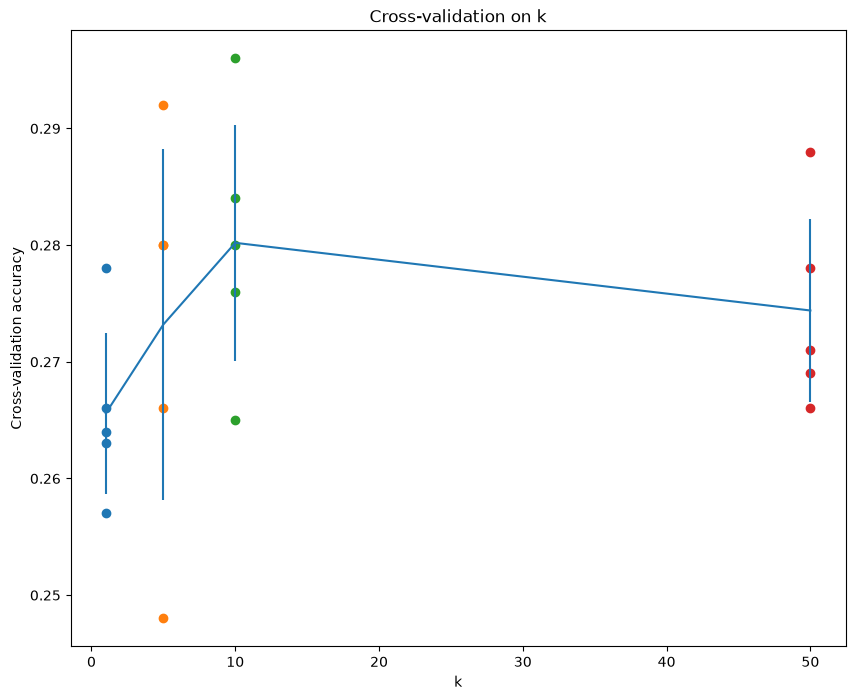

In [18]:
# plot the raw observations
for k in k_choices:
    accuracies = k_to_accuracies[k]
    plt.scatter([k] * len(accuracies), accuracies)

# plot the trend line with error bars that correspond to standard deviation
accuracies_mean = np.array([np.mean(v) for k,v in sorted(k_to_accuracies.items())])
accuracies_std = np.array([np.std(v) for k,v in sorted(k_to_accuracies.items())])
plt.errorbar(k_choices, accuracies_mean, yerr=accuracies_std)
plt.title('Cross-validation on k')
plt.xlabel('k')
plt.ylabel('Cross-validation accuracy')
plt.show()

In [19]:
# Based on the cross-validation results above, choose the best value for k,
# retrain the classifier using all the training data, 
# and test it on the test data.

best_k = k_choices[np.argmax(accuracies_mean)]

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)
y_test_pred = classifier.predict(X_test, k=best_k)

# Compute and display the accuracy
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 141 / 1000 correct => accuracy: 0.141000


In [20]:
# Use the same k found from cross-validation,
# but now use the L1 distance metric instead of
# the default L2 distance metric.
best_k = k_choices[np.argmax(accuracies_mean)]

classifier = KNearestNeighbor()
classifier.train(X_train, y_train)
y_test_pred = classifier.predict(X_test, k=best_k, distance_metric='l1')

# Compute and display the accuracy
num_correct = np.sum(y_test_pred == y_test)
accuracy = float(num_correct) / num_test
print('Got %d / %d correct => accuracy: %f' % (num_correct, num_test, accuracy))

Got 139 / 1000 correct => accuracy: 0.139000
